<a href="https://colab.research.google.com/github/official-pam/Ajatrade-on-N-Atlas/blob/main/classification_heart_disease.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Aim**

Which patient characteristics are the strongest indicators of heart disease, and which machine learning model provides the most accurate prediction of heart disease risk?


---





## **Loading and Understanding the Dataset**
---



In [90]:
!unzip -o heartdisease.zip -d heart_data
!ls heart_data


Archive:  heartdisease.zip
  inflating: heart_data/Index        
  inflating: heart_data/WARNING      
  inflating: heart_data/ask-detrano  
  inflating: heart_data/bak          
  inflating: heart_data/cleve.mod    
  inflating: heart_data/cleveland.data  
  inflating: heart_data/costs/Index  
  inflating: heart_data/costs/heart-disease.README  
  inflating: heart_data/costs/heart-disease.cost  
  inflating: heart_data/costs/heart-disease.delay  
  inflating: heart_data/costs/heart-disease.expense  
  inflating: heart_data/costs/heart-disease.group  
  inflating: heart_data/heart-disease.names  
  inflating: heart_data/hungarian.data  
  inflating: heart_data/long-beach-va.data  
  inflating: heart_data/new.data     
  inflating: heart_data/processed.cleveland.data  
  inflating: heart_data/processed.hungarian.data  
  inflating: heart_data/processed.switzerland.data  
  inflating: heart_data/processed.va.data  
  inflating: heart_data/reprocessed.hungarian.data  
  inflating: heart_d

In [91]:
!head -3 heart_data/processed.cleveland.data

63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1


In [92]:
!sed -n '108,125p' heart_data/heart-disease.names


7. Attribute Information:
   -- Only 14 used
      -- 1. #3  (age)       
      -- 2. #4  (sex)       
      -- 3. #9  (cp)        
      -- 4. #10 (trestbps)  
      -- 5. #12 (chol)      
      -- 6. #16 (fbs)       
      -- 7. #19 (restecg)   
      -- 8. #32 (thalach)   
      -- 9. #38 (exang)     
      -- 10. #40 (oldpeak)   
      -- 11. #41 (slope)     
      -- 12. #44 (ca)        
      -- 13. #51 (thal)      
      -- 14. #58 (num)       (the predicted attribute)



In [93]:
import pandas as pd
import numpy as np
columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"
]

df = pd.read_csv("heart_data/processed.cleveland.data",
                 header=None, names=columns, na_values="?")

print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [94]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [95]:
df.nunique()

,0
age,41
sex,2
cp,4
trestbps,50
chol,152
fbs,2
restecg,3
thalach,91
exang,2
oldpeak,40


In [96]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


### Data Description

| Feature | Description | Type | Values / Units |
|---|---|---|---|
| `age` | Age of the patient | Continuous | Years |
| `sex` | Sex of the patient | Binary | 1 = male, 0 = female |
| `cp` | Chest pain type | Categorical | 1 = typical angina, 2 = atypical angina, 3 = non-anginal pain, 4 = asymptomatic |
| `trestbps` | Resting blood pressure on admission to hospital | Continuous | mm Hg |
| `chol` | Serum cholesterol | Continuous | mg/dl |
| `fbs` | Fasting blood sugar greater than 120 mg/dl | Binary | 1 = true, 0 = false |
| `restecg` | Resting electrocardiogram (ECG) result | Categorical | 0 = normal, 1 = ST-T wave abnormality, 2 = left ventricular hypertrophy |
| `thalach` | Maximum heart rate achieved during exercise test | Continuous | Beats per minute |
| `exang` | Chest pain (angina) caused by exercise | Binary | 1 = yes, 0 = no |
| `oldpeak` | ST depression caused by exercise relative to rest | Continuous | Millimetres on ECG |
| `slope` | Slope of the peak exercise ST segment | Categorical | 1 = upsloping, 2 = flat, 3 = downsloping |
| `ca` | Number of major blood vessels coloured by fluoroscopy | Ordinal | 0–3 |
| `thal` | Thallium stress test result | Categorical | 3 = normal, 6 = fixed defect, 7 = reversible defect |
| `num` | **Target**: diagnosis of heart disease | Ordinal (to be converted to binary) | 0 = no disease, 1–4 = disease present (increasing severity) |

*Source: Janosi, A., Steinbrunn, W., Pfisterer, M., & Detrano, R. (1988). Heart Disease [Dataset]. UCI Machine Learning Repository. Attribute definitions from `heart-disease.names`.*

In [97]:
df["num"].value_counts().sort_index()

,count
num,
0,164
1,55
2,36
3,35
4,13


The Cleveland dataset contains 303 patient records with 13 predictor variables and 1 target. Although all variables are stored numerically, 8 of them are categorical or binary codes rather than continuous measurements. Missing values were found in ca (4) and thal (2). The target num has five levels (0–4) and will be converted to a binary indicator of disease presence, following the dataset documentation. Several extreme values were noted in chol, trestbps and oldpeak for later outlier analysis. The sample is 68% male.


# **Creating the Target & Exploratory Data Analysis**

**Create the binary target**

> target: 0 = no disease, 1 = disease (any num from 1 to 4).



In [98]:
# 1 if any level of disease (num = 1,2,3,4), otherwise 0
df["target"] = (df["num"] > 0).astype(int)

# Check it worked: compare old and new columns
print(pd.crosstab(df["num"], df["target"]))

# Class balance: counts and percentages
print("\nCounts:")
print(df["target"].value_counts())
print("\nPercentages:")
print(df["target"].value_counts(normalize=True).round(3) * 100)

target    0   1
num            
0       164   0
1         0  55
2         0  36
3         0  35
4         0  13

Counts:
target
0    164
1    139
Name: count, dtype: int64

Percentages:
target
0    54.1
1    45.9
Name: proportion, dtype: float64


**Plot the class balance**


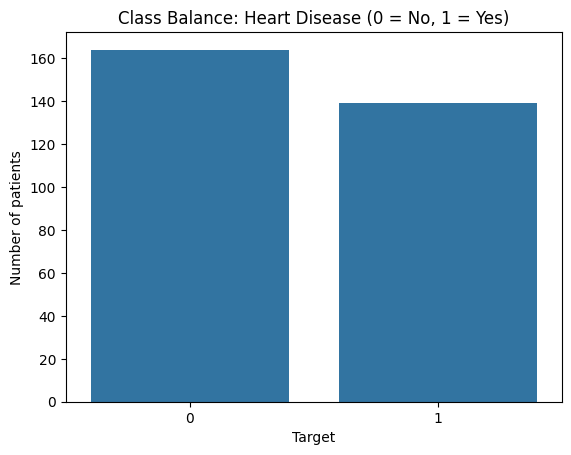

In [99]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x="target", data=df)
plt.title("Class Balance: Heart Disease (0 = No, 1 = Yes)")
plt.xlabel("Target")
plt.ylabel("Number of patients")
plt.show()

**Histograms of the continuous features**

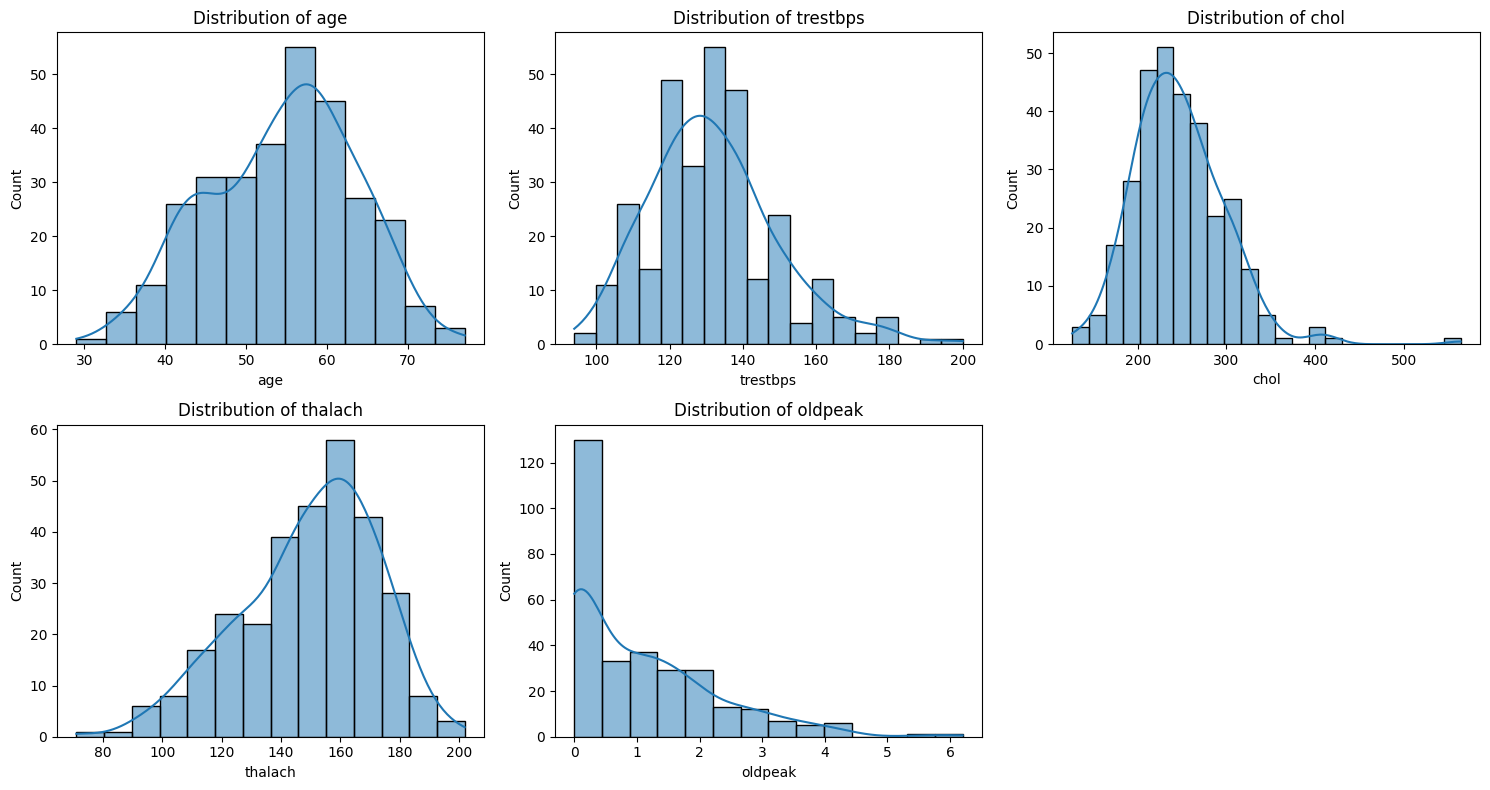

Skewness:
age        -0.21
trestbps    0.71
chol        1.14
thalach    -0.54
oldpeak     1.27
dtype: float64


In [100]:
continuous = ["age", "trestbps", "chol", "thalach", "oldpeak"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
# axes = axes.flatten() arranging several plots in one figure
for i, col in enumerate(continuous):
    sns.histplot(df[col], kde=True, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")
# Kernel Density Estimate is kde
axes[-1].set_visible(False)   # hide the empty 6th panel
plt.tight_layout()
plt.show()

# Skewness: 0 = symmetric, > 0 = right-skewed, < 0 = left-skewed
print("Skewness:")
print(df[continuous].skew().round(2))

**Count plots of the categorical**


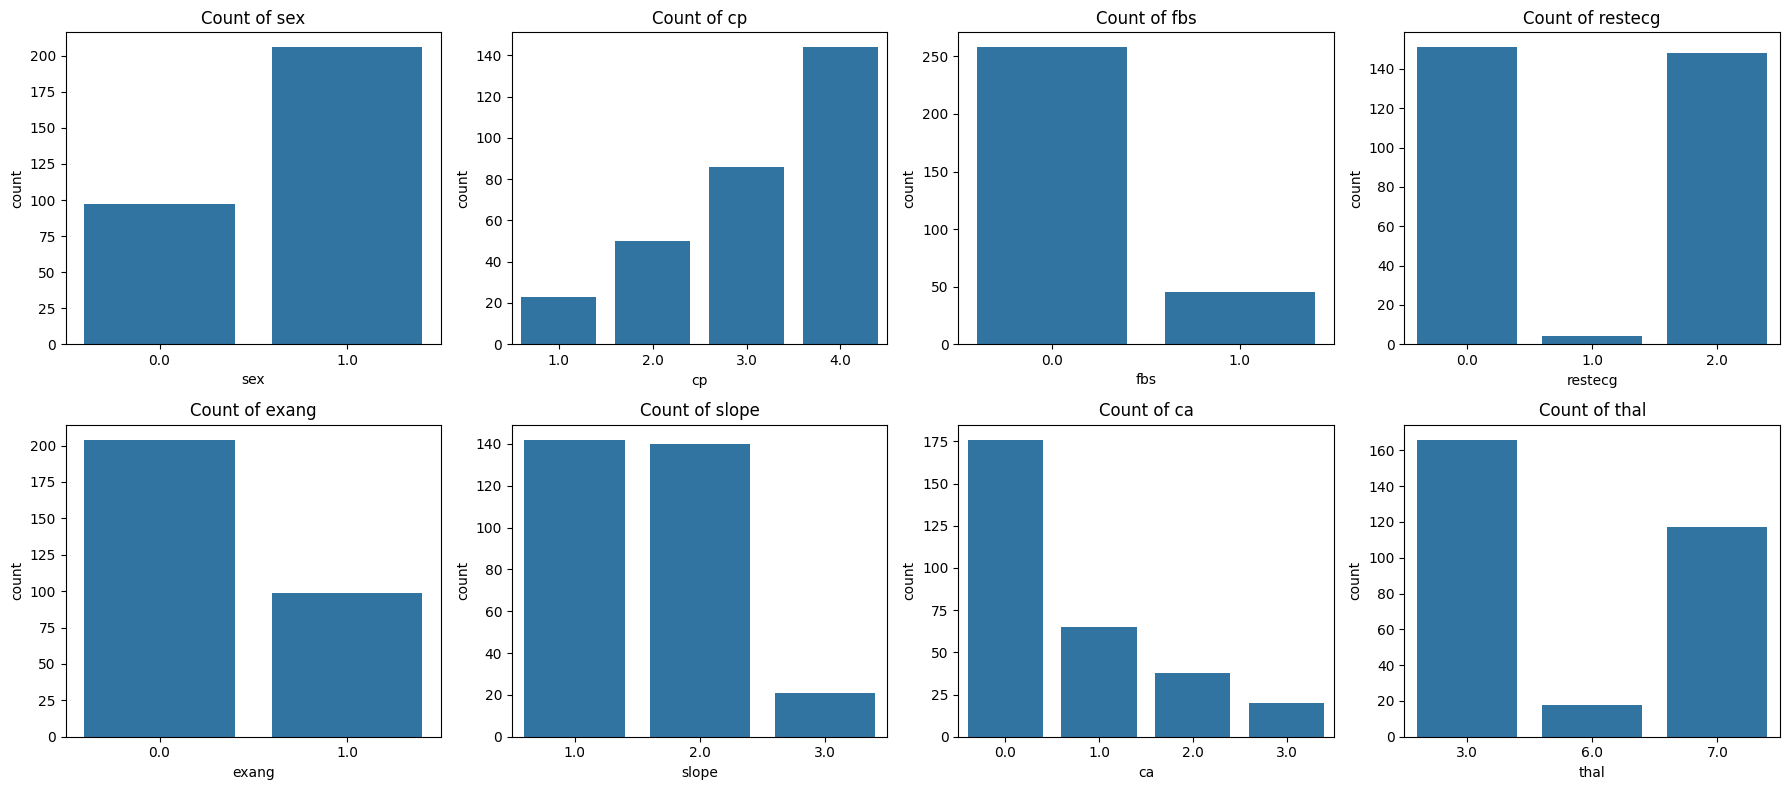

In [101]:
categorical = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(categorical):
    sns.countplot(x=col, data=df, ax=axes[i])
    axes[i].set_title(f"Count of {col}")

plt.tight_layout()
plt.show()

The binary target shows a reasonably balanced split (54.1% no disease, 45.9% disease), giving a majority-class baseline accuracy of 54.1%. Among continuous features, age is approximately symmetric, while chol (skew = 1.14) and oldpeak (skew = 1.27) are right-skewed; oldpeak has a large concentration at zero. Several categorical features contain rare categories, notably restecg = 1 (n = 4) and thal = 6 (n = 18). The sample is predominantly male (68%), and the most common chest pain type is asymptomatic (47.5%).

# **Bivariate EDA (Each Feature vs the Target)**

**Average of each continuous feature, by group**

In [102]:
continuous = ["age", "trestbps", "chol", "thalach", "oldpeak"]

group_means = df.groupby("target")[continuous].mean().round(2)
print(group_means)

          age  trestbps    chol  thalach  oldpeak
target                                           
0       52.59    129.25  242.64   158.38     0.59
1       56.63    134.57  251.47   139.26     1.57


**Box plots of continuous features by target**

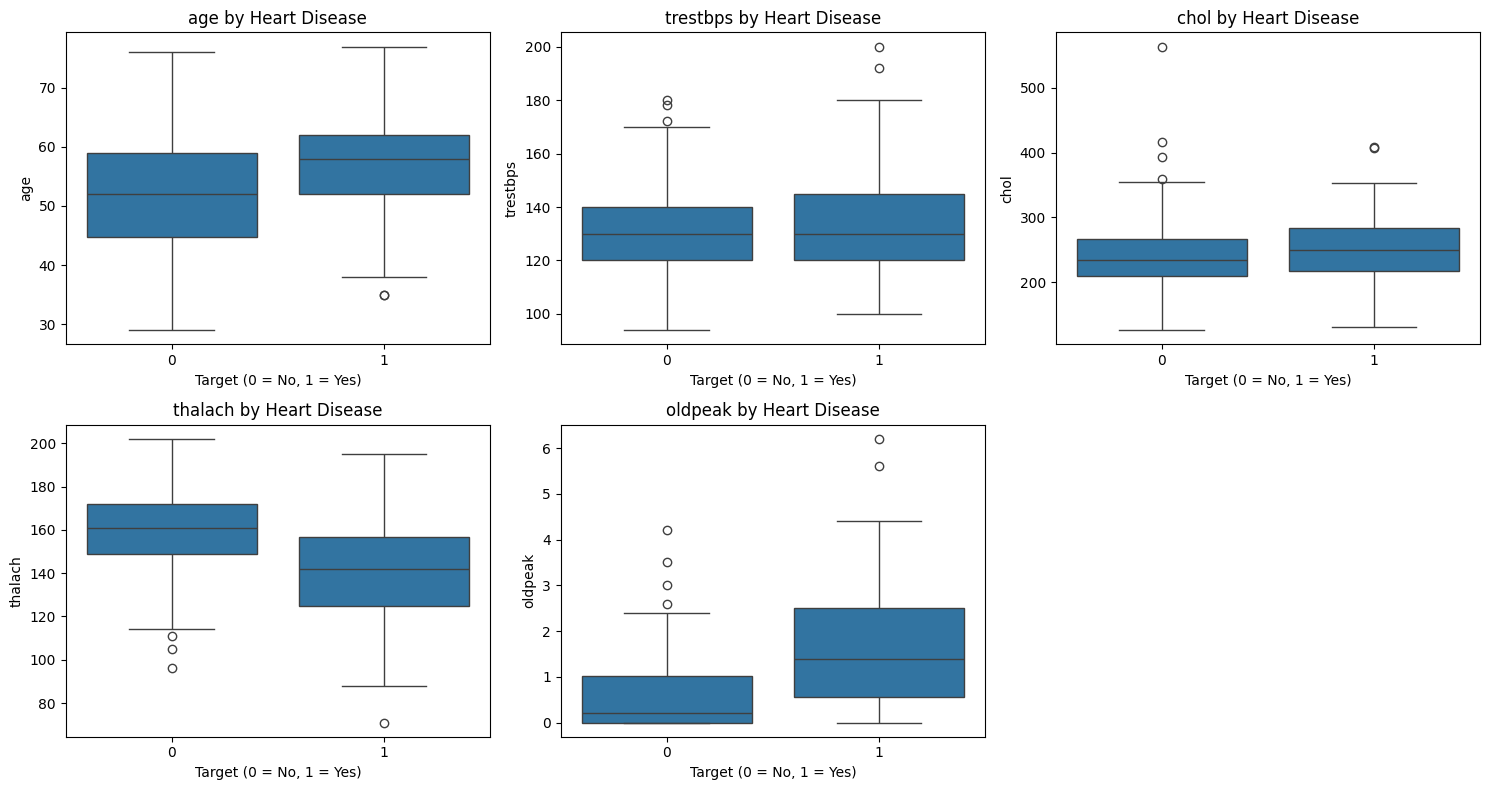

In [103]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(continuous):
    sns.boxplot(x="target", y=col, data=df, ax=axes[i])
    axes[i].set_title(f"{col} by Heart Disease")
    axes[i].set_xlabel("Target (0 = No, 1 = Yes)")

axes[-1].set_visible(False)
plt.tight_layout()
plt.show()

**Disease rate in each category**

In [104]:
categorical = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

for col in categorical:
    rate = pd.crosstab(df[col], df["target"], normalize="index") * 100
    print(f"\n===== {col} =====")
    print(rate.round(1))


===== sex =====
target     0     1
sex               
0.0     74.2  25.8
1.0     44.7  55.3

===== cp =====
target     0     1
cp                
1.0     69.6  30.4
2.0     82.0  18.0
3.0     79.1  20.9
4.0     27.1  72.9

===== fbs =====
target     0     1
fbs               
0.0     54.7  45.3
1.0     51.1  48.9

===== restecg =====
target      0     1
restecg            
0.0      62.9  37.1
1.0      25.0  75.0
2.0      45.9  54.1

===== exang =====
target     0     1
exang             
0.0     69.1  30.9
1.0     23.2  76.8

===== slope =====
target     0     1
slope             
1.0     74.6  25.4
2.0     35.0  65.0
3.0     42.9  57.1

===== ca =====
target     0     1
ca                
0.0     73.9  26.1
1.0     32.3  67.7
2.0     18.4  81.6
3.0     15.0  85.0

===== thal =====
target     0     1
thal              
3.0     77.7  22.3
6.0     33.3  66.7
7.0     23.9  76.1


**Grouped count plots for categorical features**

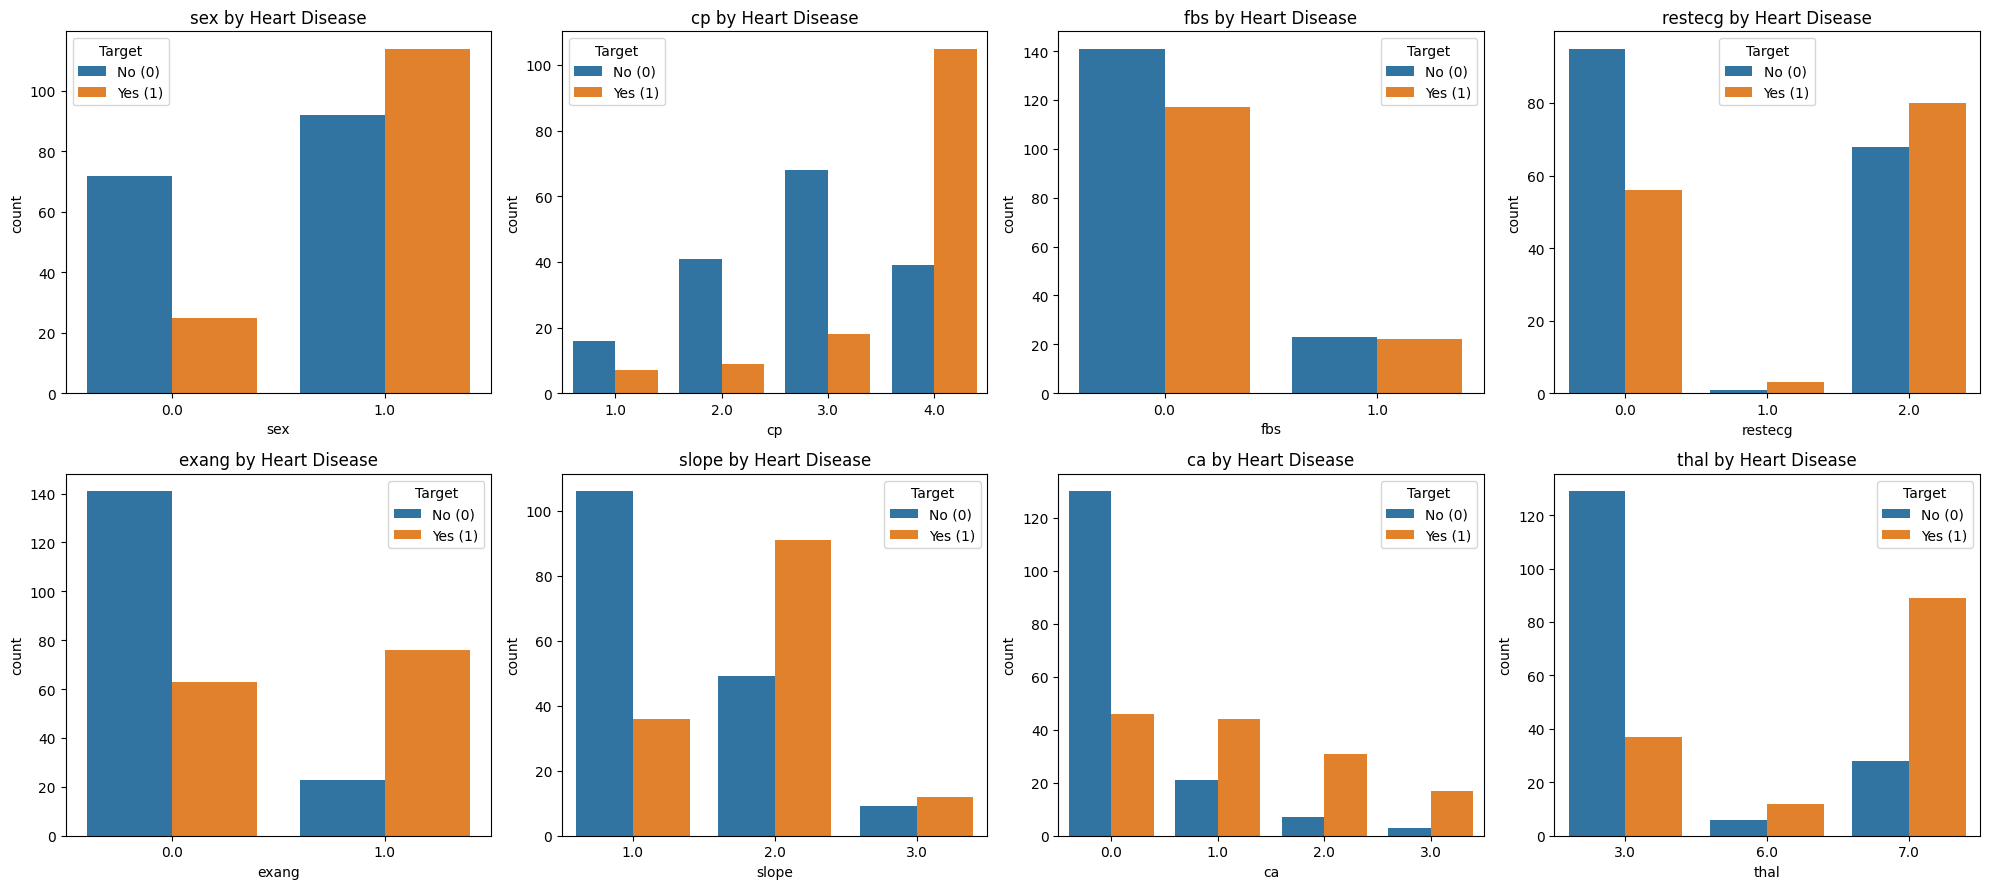

In [105]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.flatten()

for i, col in enumerate(categorical):
    sns.countplot(x=col, hue="target", data=df, ax=axes[i])
    axes[i].set_title(f"{col} by Heart Disease")
    axes[i].legend(title="Target", labels=["No (0)", "Yes (1)"])

plt.tight_layout()
plt.show()

Disease prevalence differed substantially across categories of ca, cp, thal, exang and slope. The number of major vessels (ca) showed a clear monotonic relationship with disease (26.1% at 0 vessels to 85.0% at 3 vessels). Asymptomatic chest pain (cp = 4) had the highest disease rate (72.9%), likely reflecting referral bias in the angiography population. Fasting blood sugar (fbs) showed negligible association (45.3% vs 48.9%). Rates for small categories (e.g., restecg = 1, n = 4) should be interpreted with caution.

# **Missing Values**

In [106]:
# Which rows have any missing value?
missing_rows = df[df.isnull().any(axis=1)]
print(f"Rows with missing values: {len(missing_rows)}")
print(missing_rows[["age", "sex", "cp", "ca", "thal", "target"]])

# What share of the data is that?
print(f"\nPercentage of data: {len(missing_rows) / len(df) * 100:.1f}%")

Rows with missing values: 6
      age  sex   cp   ca  thal  target
87   53.0  0.0  3.0  0.0   NaN       0
166  52.0  1.0  3.0  NaN   3.0       0
192  43.0  1.0  4.0  NaN   7.0       1
266  52.0  1.0  4.0  0.0   NaN       1
287  58.0  1.0  2.0  NaN   7.0       0
302  38.0  1.0  3.0  NaN   3.0       0

Percentage of data: 2.0%


In [107]:
# ----- Option A: drop rows -----
df_drop = df.dropna()
print("Option A - Drop")
print("Shape:", df_drop.shape)
print("Class balance (%):")
print((df_drop["target"].value_counts(normalize=True) * 100).round(1))

# ----- Option B: fill with the mode -----
df_fill = df.copy()
for col in ["ca", "thal"]:
    mode_value = df_fill[col].mode()[0]
    df_fill[col] = df_fill[col].fillna(mode_value)
    print(f"\n{col}: filled with mode = {mode_value}")

print("\nOption B - Fill")
print("Shape:", df_fill.shape)
print("Missing values remaining:", df_fill.isnull().sum().sum())

Option A - Drop
Shape: (297, 15)
Class balance (%):
target
0    53.9
1    46.1
Name: proportion, dtype: float64

ca: filled with mode = 0.0

thal: filled with mode = 3.0

Option B - Fill
Shape: (303, 15)
Missing values remaining: 0


Six records (2%) with missing values in ca (4) and thal (2) were removed. Given the small proportion, deletion was preferred over imputation to avoid introducing artificial values and data leakage; the class distribution was unchanged (53.9% vs 46.1%)


In [108]:
   df = df.dropna().reset_index(drop=True)
   print(df.shape)

(297, 15)


# **Outlier Analysis**

Method: the IQR rule

IQR = Q3 − Q1 (the spread of the middle 50% of the data)
A value is an outlier if it’s below Q1 − 1.5×IQR or above Q3 + 1.5×IQR
We only check continuous features. Outliers don’t apply to category codes.

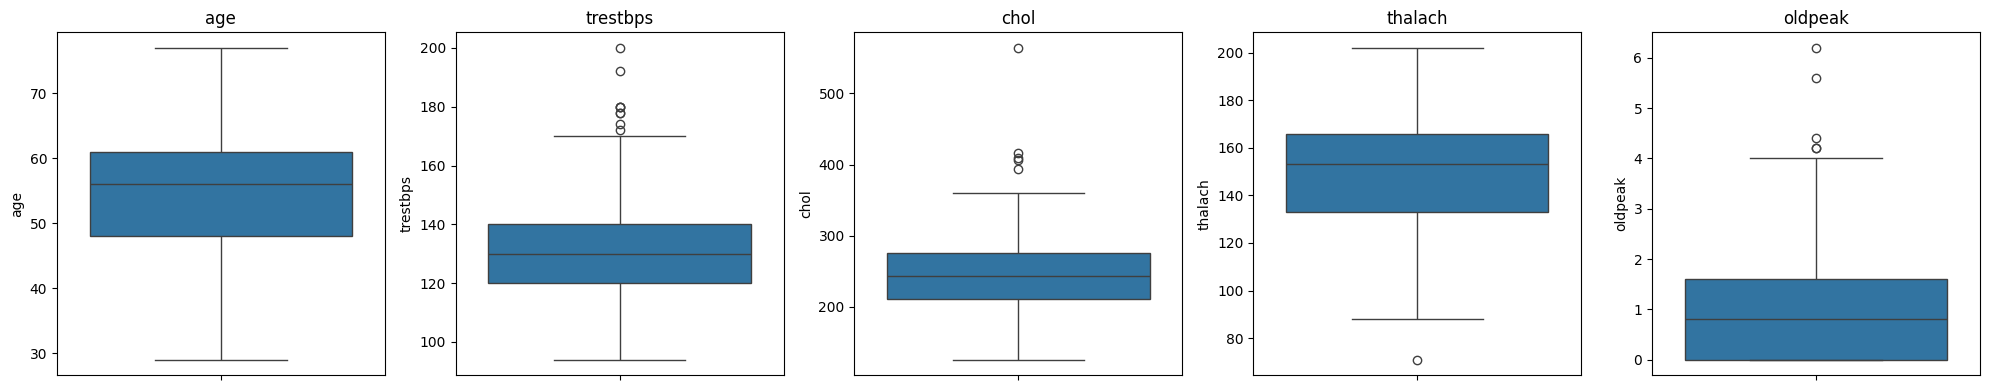

age: bounds [28.5, 80.5] | outliers = 0 | values = [] | target = []
trestbps: bounds [90.0, 170.0] | outliers = 9 | values = [172.0, 174.0, 178.0, 178.0, 180.0, 180.0, 180.0, 192.0, 200.0] | target = [0, 1, 1, 1, 0, 1, 0, 1, 1]
chol: bounds [113.5, 373.5] | outliers = 5 | values = [394.0, 407.0, 409.0, 417.0, 564.0] | target = [0, 1, 0, 0, 1]
thalach: bounds [83.5, 215.5] | outliers = 1 | values = [71.0] | target = [1]
oldpeak: bounds [-2.4, 4.0] | outliers = 5 | values = [4.2, 4.2, 4.4, 5.6, 6.2] | target = [1, 1, 0, 1, 1]


In [109]:
continuous = ["age", "trestbps", "chol", "thalach", "oldpeak"]

# Box plots: dots beyond the whiskers are outliers
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for i, col in enumerate(continuous):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(col)
plt.tight_layout()
plt.show()

# IQR rule: count the outliers and see which class they belong to
for col in continuous:
    Q1, Q3 = df[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    out = df[(df[col] < lower) | (df[col] > upper)]
    print(f"{col}: bounds [{lower:.1f}, {upper:.1f}] | outliers = {len(out)} "
          f"| values = {sorted(out[col].tolist())} | target = {out['target'].tolist()}")

Outliers were identified with the IQR method in trestbps (9), chol (5), oldpeak (5) and thalach (1); none in age. All values are clinically plausible and most belong to patients with heart disease, so they were retained as genuine observations rather than errors. Their influence is addressed through feature scaling and the use of outlier-robust tree-based models.

# **Correlation Analysis**

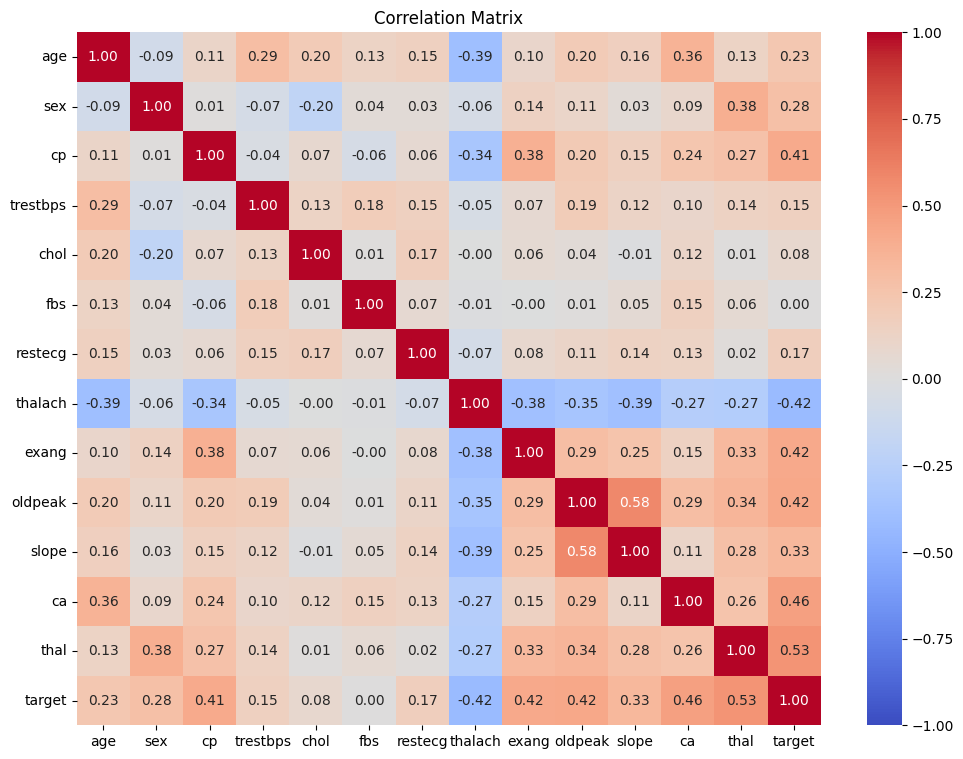

thal        0.53
ca          0.46
oldpeak     0.42
thalach    -0.42
exang       0.42
cp          0.41
slope       0.33
sex         0.28
age         0.23
restecg     0.17
trestbps    0.15
chol        0.08
fbs         0.00
Name: target, dtype: float64


In [110]:
# Drop 'num': target was created from it, so it would give a fake perfect correlation
corr = df.drop(columns="num").corr()

# Heatmap
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.show()

# Correlation with target, ranked by strength
print(corr["target"].drop("target").sort_values(key=abs, ascending=False).round(2))

Pearson correlation showed the strongest associations with heart disease for thal (r = 0.53), ca (0.46), oldpeak (0.42), exang (0.43), cp (0.41) and thalach (−0.42), consistent with the EDA. chol (0.09) and fbs (0.00) showed negligible correlation. The highest inter-feature correlation was between oldpeak and slope (r = 0.58); no pair exceeded 0.8, indicating no severe multicollinearity. As Pearson’s r is designed for continuous variables, results for categorical features are treated as indicative.

# **Feature Engineering**

In [111]:
df_fe = df.drop(columns="num").copy()

# Merge rare restecg category (1) into abnormal (2)
df_fe["restecg"] = df_fe["restecg"].replace({1: 2})
print(df_fe["restecg"].value_counts())

# One-hot encode nominal categorical features
df_fe = pd.get_dummies(df_fe, columns=["cp", "restecg", "slope", "thal"],
                       drop_first=True, dtype=int)

print("\nShape:", df_fe.shape)
print(df_fe.columns.tolist())
df_fe.head()

restecg
2.0    150
0.0    147
Name: count, dtype: int64

Shape: (297, 18)
['age', 'sex', 'trestbps', 'chol', 'fbs', 'thalach', 'exang', 'oldpeak', 'ca', 'target', 'cp_2.0', 'cp_3.0', 'cp_4.0', 'restecg_2.0', 'slope_2.0', 'slope_3.0', 'thal_6.0', 'thal_7.0']


,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,target,cp_2.0,cp_3.0,cp_4.0,restecg_2.0,slope_2.0,slope_3.0,thal_6.0,thal_7.0
0,63.0,1.0,145.0,233.0,1.0,150.0,0.0,2.3,0.0,0,0,0,0,1,0,1,1,0
1,67.0,1.0,160.0,286.0,0.0,108.0,1.0,1.5,3.0,1,0,0,1,1,1,0,0,0
2,67.0,1.0,120.0,229.0,0.0,129.0,1.0,2.6,2.0,1,0,0,1,1,1,0,0,1
3,37.0,1.0,130.0,250.0,0.0,187.0,0.0,3.5,0.0,0,0,1,0,0,0,1,0,0
4,41.0,0.0,130.0,204.0,0.0,172.0,0.0,1.4,0.0,0,1,0,0,1,0,0,0,0


The original severity variable num was removed to prevent target leakage. The sparse restecg category 1 (n = 4, ST-T abnormality) was merged with category 2 (left ventricular hypertrophy) to form a single “abnormal ECG” group. Nominal features (cp, restecg, slope, thal) were one-hot encoded with the first category dropped to avoid the dummy variable trap; binary features and the ordinal ca were kept as is. The final dataset contains 297 records and 17 predictor

# **Train/Test Split**

In [112]:
from sklearn.model_selection import train_test_split

X = df_fe.drop(columns="target")   # features
y = df_fe["target"]                # target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("\nTrain class balance (%):")
print((y_train.value_counts(normalize=True) * 100).round(1))
print("\nTest class balance (%):")
print((y_test.value_counts(normalize=True) * 100).round(1))

X_train: (237, 17) | X_test: (60, 17)

Train class balance (%):
target
0    54.0
1    46.0
Name: proportion, dtype: float64

Test class balance (%):
target
0    53.3
1    46.7
Name: proportion, dtype: float64


The data was split into training (80%, n = 237) and test (20%, n = 60) sets using stratified sampling to preserve the class distribution (54.0%/46.0% train; 53.3%/46.7% test). A fixed random seed (42) ensured reproducibility. All subsequent preprocessing was fitted on the training set only to prevent data leakage.

# **Scaling (Normalization vs Standardization)**

In [113]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]

# ----- Normalization (Min-Max) -----
mm = MinMaxScaler()
X_train_mm, X_test_mm = X_train.copy(), X_test.copy()
X_train_mm[num_cols] = mm.fit_transform(X_train[num_cols])   # learn + apply on train
X_test_mm[num_cols]  = mm.transform(X_test[num_cols])        # apply only on test

# ----- Standardization (Z-score) -----
ss = StandardScaler()
X_train_std, X_test_std = X_train.copy(), X_test.copy()
X_train_std[num_cols] = ss.fit_transform(X_train[num_cols])
X_test_std[num_cols]  = ss.transform(X_test[num_cols])

print("Normalized (train):")
print(X_train_mm[num_cols].describe().loc[["mean", "std", "min", "max"]].round(2))
print("\nStandardized (train):")
print(X_train_std[num_cols].describe().loc[["mean", "std", "min", "max"]].round(2))

Normalized (train):
       age  trestbps  chol  thalach  oldpeak    ca
mean  0.48      0.36  0.28     0.58     0.17  0.23
std   0.21      0.17  0.12     0.21     0.19  0.31
min   0.00      0.00  0.00     0.00     0.00  0.00
max   1.00      1.00  1.00     1.00     1.00  1.00

Standardized (train):
       age  trestbps  chol  thalach  oldpeak    ca
mean -0.00     -0.00 -0.00    -0.00     0.00  0.00
std   1.00      1.00  1.00     1.00     1.00  1.00
min  -2.30     -2.14 -2.33    -2.77    -0.90 -0.74
max   2.47      3.79  5.93     2.02     4.37  2.53


Continuous features and ca were scaled using two methods: Min-Max normalization (range 0–1) and Z-score standardization (mean 0, SD 1). Scalers were fitted on the training set only and applied to the test set. Standardized data was used for scale-sensitive methods (Logistic Regression, SVM, PCA, RFE), normalized data for Chi-Square feature selection (which requires non-negative inputs), and unscaled data for tree-based models, which are scale-invariant.

# **Feature Selection**


              corr  anova_F    chi2  rfe_rank  rf_importance
cp_4.0       0.519   86.674  32.603         1          0.108
thal_7.0     0.489   73.864  33.959         1          0.112
oldpeak      0.434   54.409   9.380         1          0.113
ca           0.415   48.801  16.844         1          0.103
exang        0.397   43.876  24.386         1          0.044
thalach      0.374   38.273   2.506         5          0.111
slope_2.0    0.354   33.597  16.261         1          0.039
cp_3.0       0.335   29.690  19.069         1          0.032
cp_2.0       0.249   15.535  12.463         4          0.013
sex          0.242   14.680   4.527         1          0.025
age          0.199    9.687   0.853         8          0.095
restecg_2.0  0.182    8.022   3.928         1          0.022
trestbps     0.163    6.428   0.497         3          0.079
slope_3.0    0.089    1.882   1.755         1          0.006
thal_6.0     0.089    1.882   1.755         7          0.007
chol         0.066    1.

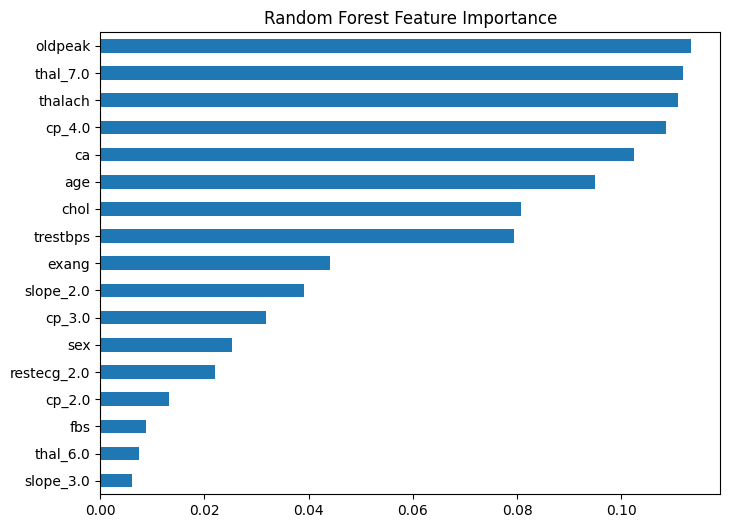

In [114]:
from sklearn.feature_selection import SelectKBest, f_classif, chi2, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

K = 10
scores = pd.DataFrame(index=X_train.columns)

# 1. Correlation
scores["corr"] = X_train.corrwith(y_train).abs()
# 2. SelectKBest (ANOVA F-test)
scores["anova_F"] = SelectKBest(f_classif, k=K).fit(X_train_std, y_train).scores_
# 3. Chi-Square
scores["chi2"] = SelectKBest(chi2, k=K).fit(X_train_mm, y_train).scores_
# 4. RFE with Logistic Regression
rfe = RFE(LogisticRegression(max_iter=1000), n_features_to_select=K).fit(X_train_std, y_train)
scores["rfe_rank"] = rfe.ranking_          # 1 = selected
# 5. Random Forest feature importance
rf = RandomForestClassifier(n_estimators=300, random_state=42).fit(X_train, y_train)
scores["rf_importance"] = rf.feature_importances_

print(scores.round(3).sort_values("anova_F", ascending=False))

# ----- Voting: was the feature in each method's top 10? -----
votes = pd.DataFrame(index=X_train.columns)
votes["corr"]  = scores["corr"].rank(ascending=False) <= K
votes["anova"] = scores["anova_F"].rank(ascending=False) <= K
votes["chi2"]  = scores["chi2"].rank(ascending=False) <= K
votes["rfe"]   = rfe.support_
votes["rf"]    = scores["rf_importance"].rank(ascending=False) <= K
votes["total"] = votes.sum(axis=1)
print(votes.sort_values("total", ascending=False))

# Bar chart of Random Forest importance
scores["rf_importance"].sort_values().plot(kind="barh", figsize=(8, 6),
                                           title="Random Forest Feature Importance")
plt.show()

In [115]:
selected = votes[votes["total"] >= 3].index.tolist()
print(len(selected), selected)

10 ['sex', 'thalach', 'exang', 'oldpeak', 'ca', 'cp_2.0', 'cp_3.0', 'cp_4.0', 'slope_2.0', 'thal_7.0']


Five feature selection methods were applied to the training data: Pearson correlation, SelectKBest (ANOVA F-test), Chi-Square, Recursive Feature Elimination with Logistic Regression, and Random Forest feature importance. Each selected its top 10 features, and features chosen by at least three methods were retained (10 of 17). Six features (cp_4.0, thal_7.0, oldpeak, ca, exang, slope_2.0) were selected unanimously, while fbs was selected by none. age, chol and trestbps were ranked highly only by Random Forest, suggesting possible non-linear effects.

# **PCA (Principal Component Analysis)**

Variance per PC (%): [27.2 15.2 11.2  9.9  9.4  6.   4.3  3.2  2.9  2.5  2.1  1.7  1.6  1.4
  0.6  0.4  0.3]
Cumulative (%):      [ 27.2  42.4  53.6  63.5  72.9  78.8  83.1  86.4  89.3  91.8  94.   95.7
  97.3  98.7  99.3  99.7 100. ]


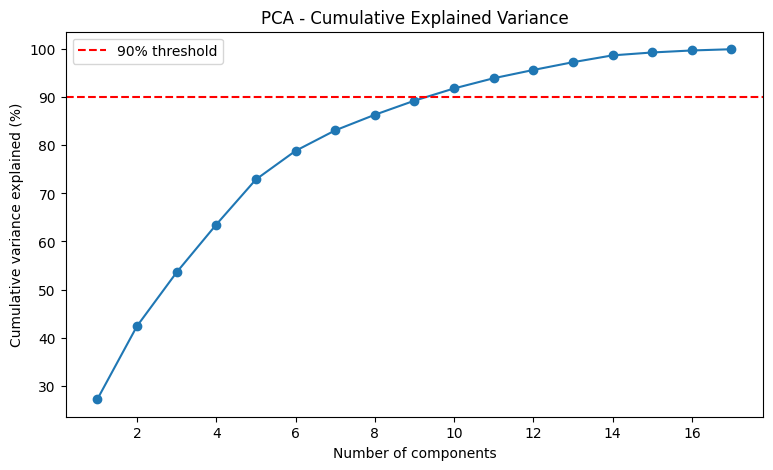

Components kept: 10
X_train_pca: (237, 10) | X_test_pca: (60, 10)


In [116]:
from sklearn.decomposition import PCA
import numpy as np

# Fit PCA on all components to see variance explained
pca_full = PCA().fit(X_train_std)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

print("Variance per PC (%):", (pca_full.explained_variance_ratio_ * 100).round(1))
print("Cumulative (%):     ", (cum_var * 100).round(1))

# Scree plot
plt.figure(figsize=(9, 5))
plt.plot(range(1, len(cum_var) + 1), cum_var * 100, marker="o")
plt.axhline(90, color="red", linestyle="--", label="90% threshold")
plt.xlabel("Number of components")
plt.ylabel("Cumulative variance explained (%)")
plt.title("PCA - Cumulative Explained Variance")
plt.legend()
plt.show()

# Keep enough components for 90% variance (fit on train, apply to test)
pca = PCA(n_components=0.90)
X_train_pca = pca.fit_transform(X_train_std)
X_test_pca  = pca.transform(X_test_std)

print("Components kept:", pca.n_components_)
print("X_train_pca:", X_train_pca.shape, "| X_test_pca:", X_test_pca.shape)

PCA was applied to the standardized training data. The first component explained 27.2% of the variance, and 10 components were required to retain at least 90% (91.8%), reducing dimensionality from 17 to 10. The spread of variance across components indicates limited redundancy among the original features, consistent with the correlation analysis. Because principal components are not clinically interpretable and most inputs are binary, PCA-transformed data is evaluated as an alternative input rather than the primary feature set.

# **Classification Models**

In [117]:
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score

def get_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=1000),
        "Naive Bayes": GaussianNB(),
        "SVM": SVC(kernel="rbf", probability=True, random_state=42),
        "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
        "XGBoost": XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1,
                                 eval_metric="logloss", random_state=42),
    }
scaled_models = ["Logistic Regression", "Naive Bayes", "SVM"]

# (scaled train, scaled test, unscaled train, unscaled test)
feature_sets = {
    "All 17":      (X_train_std, X_test_std, X_train, X_test),
    "Selected 10": (X_train_std[selected], X_test_std[selected],
                    X_train[selected], X_test[selected]),
    "PCA 10":      (X_train_pca, X_test_pca, X_train_pca, X_test_pca),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for set_name, (Xtr_s, Xte_s, Xtr_u, Xte_u) in feature_sets.items():
    for model_name, model in get_models().items():
        Xtr, Xte = (Xtr_s, Xte_s) if model_name in scaled_models else (Xtr_u, Xte_u)
        cv_acc = cross_val_score(model, Xtr, y_train, cv=cv).mean()
        model.fit(Xtr, y_train)
        test_acc = accuracy_score(y_test, model.predict(Xte))
        results.append([set_name, model_name, round(cv_acc * 100, 1), round(test_acc * 100, 1)])

results_df = pd.DataFrame(results, columns=["Feature set", "Model", "CV acc (%)", "Test acc (%)"])
print(results_df.pivot(index="Model", columns="Feature set", values=["CV acc (%)", "Test acc (%)"]))

                    CV acc (%)                    Test acc (%)         \
Feature set             All 17 PCA 10 Selected 10       All 17 PCA 10   
Model                                                                   
Logistic Regression       81.4   81.8        81.9         86.7   83.3   
Naive Bayes               79.3   75.9        80.6         78.3   88.3   
Random Forest             80.6   81.0        80.6         83.3   86.7   
SVM                       81.0   80.6        83.6         86.7   88.3   
XGBoost                   79.7   76.8        78.5         85.0   83.3   

                                 
Feature set         Selected 10  
Model                            
Logistic Regression        88.3  
Naive Bayes                81.7  
Random Forest              76.7  
SVM                        88.3  
XGBoost                    80.0  


Five classifiers were trained on three feature sets and assessed with 5-fold stratified cross-validation on the training data and accuracy on the held-out test set. All models substantially exceeded the 54% majority-class baseline. Linear models performed as well as or better than ensemble methods, with SVM on the 10 selected features achieving the highest cross-validated accuracy (83.6%) and 88.3% test accuracy, and Logistic Regression achieving comparable results (81.9% CV, 88.3% test). PCA did not consistently improve performance. Given the small test set (n = 60), cross-validated accuracy was treated as the primary comparison metric.

# **Model Evaluation**

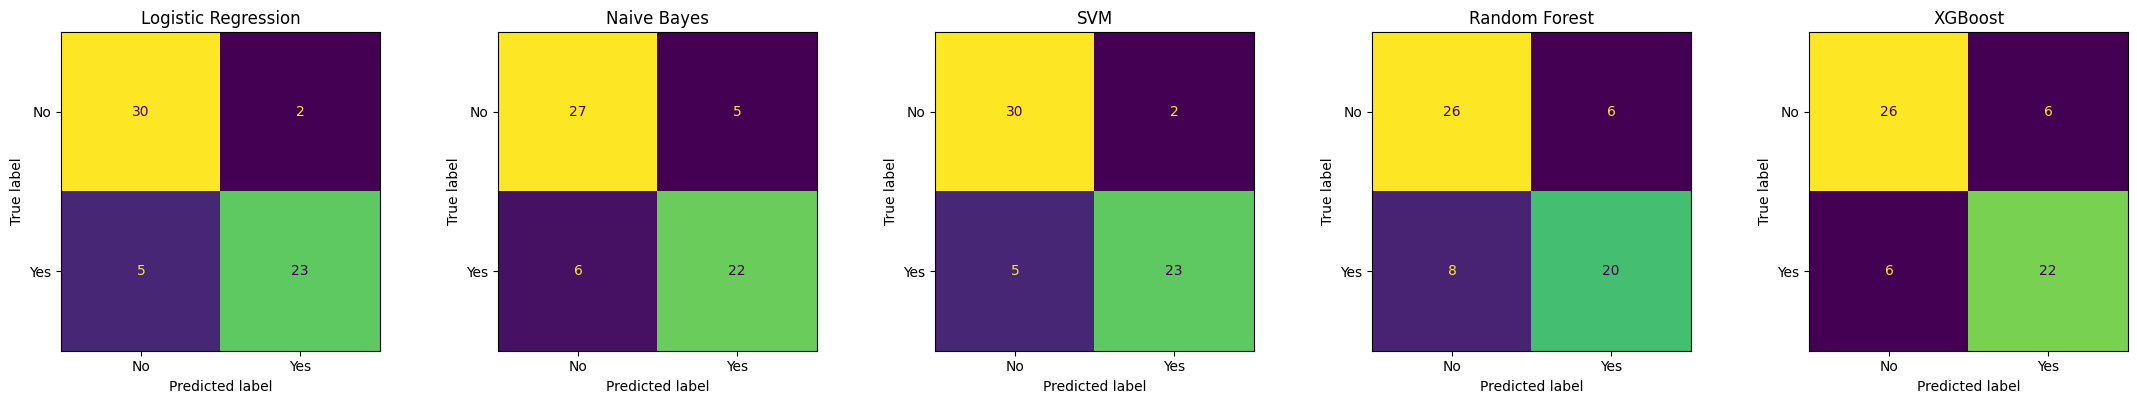

              Model  Accuracy  Precision  Recall    F1  ROC-AUC
                SVM     0.883      0.920   0.821 0.868    0.964
Logistic Regression     0.883      0.920   0.821 0.868    0.962
        Naive Bayes     0.817      0.815   0.786 0.800    0.919
      Random Forest     0.767      0.769   0.714 0.741    0.907
            XGBoost     0.800      0.786   0.786 0.786    0.907


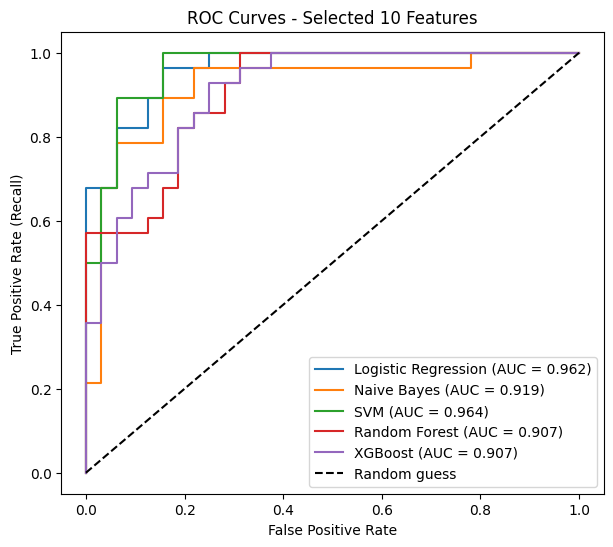

In [118]:
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve,
                             ConfusionMatrixDisplay)

eval_rows, roc_data = [], {}
fig, axes = plt.subplots(1, 5, figsize=(22, 4))

for i, (name, model) in enumerate(get_models().items()):
    if name in scaled_models:
        Xtr, Xte = X_train_std[selected], X_test_std[selected]
    else:
        Xtr, Xte = X_train[selected], X_test[selected]

    model.fit(Xtr, y_train)
    y_pred = model.predict(Xte)
    y_prob = model.predict_proba(Xte)[:, 1]      # probability of disease

    eval_rows.append([name,
                      accuracy_score(y_test, y_pred),
                      precision_score(y_test, y_pred),
                      recall_score(y_test, y_pred),
                      f1_score(y_test, y_pred),
                      roc_auc_score(y_test, y_prob)])
    roc_data[name] = roc_curve(y_test, y_prob)

    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                           display_labels=["No", "Yes"]).plot(ax=axes[i], colorbar=False)
    axes[i].set_title(name)

plt.tight_layout()
plt.show()

eval_df = pd.DataFrame(eval_rows, columns=["Model", "Accuracy", "Precision",
                                           "Recall", "F1", "ROC-AUC"]).round(3)
print(eval_df.sort_values("ROC-AUC", ascending=False).to_string(index=False))

# ROC curves
plt.figure(figsize=(7, 6))
for name, (fpr, tpr, _) in roc_data.items():
    auc = eval_df.loc[eval_df["Model"] == name, "ROC-AUC"].values[0]
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves - Selected 10 Features")
plt.legend()
plt.show()

Models were evaluated on the held-out test set (n = 60) using the 10 selected features. Logistic Regression and SVM performed best (accuracy 0.883, precision 0.920, recall 0.821, F1 0.868), with ROC-AUC of 0.962 and 0.964 respectively. Ensemble models performed worse, with Random Forest missing the most diseased patients (8 false negatives). Given equivalent performance, Logistic Regression was selected as the final model for its interpretability. Because false negatives carry the greatest clinical cost, recall was prioritized; future work could lower the classification threshold to improve sensitivity.

# **My overall Conclusion**

This study shows that heart disease can be predicted with high accuracy (88%, ROC-AUC 0.96) from routine clinical measurements, with Logistic Regression offering the best balance of performance and interpretability. Exercise stress test findings (thallium defects, ST depression, exercise-induced angina, reduced maximum heart rate) together with the number of affected vessels were the dominant predictors, while traditional risk factors such as cholesterol and blood sugar contributed little in this referred population. The results support the use of simple, interpretable models as clinical decision-support tools, but the small, male-dominated and referral-based sample limits generalization, and the model’s sensitivity (82%) would need improvement before clinical use.
